## Dependency Parsing



**Dependency Parsing** is the process of analyzing the grammatical structure of a sentence to identify the syntactic relations between "head" words and words that modify them (their "dependents"). Instead of grouping words into nested phrases (like constituency parsing), dependency parsing connects words directly with directed, labeled arcs.

#### Why is it Important?
- **Extracting Meaning:** It identifies "who did what to whom" by linking subjects, verbs, objects, and their modifiers.
- **Downstream NLP Tasks:** Essential for relation extraction, information extraction, machine translation, and question answering.
- **Language Variety:** Highly effective for morphologically rich languages with free word order, where phrase-structure rules are harder to define.

In [6]:
!pip install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 45.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [7]:
import spacy

# Load the small English model
nlp = spacy.load("en_core_web_sm")

# Process your text
doc = nlp("The quick brown fox jumps over the lazy dog.")

# Print the token, dependency label, and its head word
print(f"{'Token':<10} | {'Dependency':<12} | {'Head Word':<10}")
print("-" * 40)
for token in doc:
    print(f"{token.text:<10} | {token.dep_:<12} | {token.head.text:<10}")

Token      | Dependency   | Head Word 
----------------------------------------
The        | det          | fox       
quick      | amod         | fox       
brown      | amod         | fox       
fox        | nsubj        | jumps     
jumps      | ROOT         | jumps     
over       | prep         | jumps     
the        | det          | dog       
lazy       | amod         | dog       
dog        | pobj         | over      
.          | punct        | jumps     


In [8]:
# Example: Find the root verb and its children
root_token = [token for token in doc if token.dep_ == "ROOT"][0]
print(f"Root Verb: {root_token.text}")
print(f"Immediate Dependents: {[child.text for child in root_token.children]}")

Root Verb: jumps
Immediate Dependents: ['fox', 'over', '.']


In [11]:
# Common dependency tags in SpaCy (Universal Dependencies schema)
common_deps = [
    "nsubj", "obj", "iobj", "csubj", "ccomp", "xcomp", "obl", "vocative",
    "expl", "dislocated", "advcl", "advmod", "discourse", "aux", "cop",
    "mark", "nmod", "appos", "nummod", "acl", "amod", "det", "clf",
    "case", "conj"
]

print(f"{'Tag':<12} | {'Explanation':<50}")
print("-" * 65)
for dep in common_deps:
    explanation = spacy.explain(dep)
    print(f"{dep:<12} | {explanation:<50}")

Tag          | Explanation                                       
-----------------------------------------------------------------
nsubj        | nominal subject                                   
obj          | object                                            
iobj         | indirect object                                   
csubj        | clausal subject                                   
ccomp        | clausal complement                                
xcomp        | open clausal complement                           
obl          | oblique nominal                                   
vocative     | vocative                                          
expl         | expletive                                         
dislocated   | dislocated elements                               
advcl        | adverbial clause modifier                         
advmod       | adverbial modifier                                
discourse    | discourse element                                 
aux       

In [12]:
from spacy import displacy

# 1. To view in a Jupyter Notebook:
displacy.render(doc, style="dep", options={"compact": True, "distance": 100})

# 2. To launch a local web server (accessible via http://127.0.0.1:5000):
displacy.serve(doc, style="dep")

/usr/local/lib/python3.13/dist-packages/spacy/displacy/__init__.py:107: UserWarning: [W011] It looks like you're calling displacy.serve from within a Jupyter notebook or a similar environment. This likely means you're already running a local web server, so there's no need to make displaCy start another one. Instead, you should be able to replace displacy.serve with displacy.render to show the visualization.
  warnings.warn(Warnings.W011)



Using the 'dep' visualizer
Serving on http://0.0.0.0:5000 ...

Shutting down server on port 5000.


### Transition-Based Dependency Parsing



**Transition-Based Dependency Parsing** frames the parsing process as a sequence of actions (transitions) applied to an abstract state machine. It is a highly efficient, greedy method often used in modern parser architectures.

#### Key Components:
- **Stack ($S$):** Temporarily holds processed words currently being analyzed.
- **Buffer ($B$):** Holds the sequence of remaining words to be processed.
- **Set of Dependency Arcs ($A$):** Stores the relation pairs discovered so far.

#### Arc-Standard Transitions:
1. **SHIFT:** Moves the front token of the buffer onto the stack.
2. **LEFT-ARC ($r$):** Asserts a dependency relation of type $r$ where the top element on the stack ($s_1$) is the head, and the second element ($s_2$) is the dependent. $s_2$ is then popped from the stack.
3. **RIGHT-ARC ($r$):** Asserts a dependency relation of type $r$ where $s_2$ is the head, and $s_1$ is the dependent. $s_1$ is then popped from the stack.

In [13]:
import pandas as pd

def dependency_parse(sentence, gold_heads, gold_relations):
    """
    Transition-Based Dependency Parsing (Arc-Standard)

    Parameters
    ----------
    sentence : str
        Input sentence.

    gold_heads : dict
        Mapping of token ID to its gold-standard head ID.
        Head ID 0 represents ROOT.

    gold_relations : dict
        Mapping of token ID to its dependency relation.

    Returns
    -------
    state : dict
        Final parser configuration.
    """

    # 1. Tokenize the sentence
    words = sentence.split()

    # Assign each word an ID starting from 1
    word_list = {
        i + 1: word
        for i, word in enumerate(words)
    }

    # 2. Initialize the parser state
    state = {
        "stack": [0],  # ROOT
        "buffer": list(word_list.keys()),
        "relations": []
    }

    # Find the gold-standard dependents of each word
    children = {
        i: {
            dep for dep, head in gold_heads.items()
            if head == i
        }
        for i in range(len(words) + 1)
    }

    # Track the dependents that have already been attached
    attached = set()

    # List to track steps for structured display
    steps_data = []

    # 3. Oracle: Select the next transition
    def oracle(state):

        stack = state["stack"]
        buffer = state["buffer"]

        # Need at least two words on the stack
        if len(stack) >= 2:

            s1 = stack[-1]   # Top
            s2 = stack[-2]   # Second from top

            # LEFTARC: s1 is the head of s2
            if (
                s1 != 0
                and s2 in gold_heads
                and gold_heads[s2] == s1
                and children[s2].issubset(attached)
            ):
                return "LEFTARC"

            # RIGHTARC: s2 is the head of s1
            if (
                s1 in gold_heads
                and gold_heads[s1] == s2
                and children[s1].issubset(attached)
            ):
                return "RIGHTARC"

        # SHIFT: Move the next token onto the stack
        if buffer:
            return "SHIFT"

        raise ValueError(
            "No valid transition found. "
            "Check the gold dependency annotations."
        )

    # 4. Apply the selected transition
    def apply(action, state):

        stack = state["stack"]
        buffer = state["buffer"]
        relations = state["relations"]

        relation_added = "-"

        if action == "SHIFT":
            # Move the first buffer token onto the stack
            word_id = buffer.pop(0)
            stack.append(word_id)

        elif action == "LEFTARC":
            # s1 becomes the head of s2
            head = stack[-1]
            dependent = stack[-2]
            rel_type = gold_relations[dependent]

            relations.append((
                head,
                dependent,
                rel_type
            ))
            relation_added = f"{word_list.get(head, 'ROOT')} --{rel_type}--> {word_list[dependent]}"

            # Remove the dependent
            stack.pop(-2)
            attached.add(dependent)

        elif action == "RIGHTARC":
            # s2 becomes the head of s1
            head = stack[-2]
            dependent = stack[-1]
            rel_type = gold_relations[dependent]

            relations.append((
                head,
                dependent,
                rel_type
            ))
            relation_added = f"{word_list.get(head, 'ROOT')} --{rel_type}--> {word_list[dependent]}"

            # Remove the dependent
            stack.pop()
            attached.add(dependent)

        return state, relation_added

    # Helper to format Stack/Buffer with words for readability
    def format_tokens(ids):
        return "[" + ", ".join(f"{word_list[i]}({i})" if i != 0 else "ROOT(0)" for i in ids) + "]"

    step_idx = 1
    # 5. Run the parsing process
    while state["buffer"] or len(state["stack"]) > 1:

        action = oracle(state)

        # Capture pre-transition values for visualization
        stack_str = format_tokens(state["stack"])
        buffer_str = format_tokens(state["buffer"])

        state, relation_added = apply(action, state)

        steps_data.append({
            "Step": step_idx,
            "Stack": stack_str,
            "Word List (Buffer)": buffer_str,
            "Action": action,
            "Relation Added": relation_added
        })
        step_idx += 1

    # Display parsing steps in a table
    df_steps = pd.DataFrame(steps_data)
    display(df_steps)

    # 6. Return the final dependency tree
    dependency_tree = []

    for head, dependent, relation in state["relations"]:

        head_word = (
            "ROOT" if head == 0
            else word_list[head]
        )

        dependent_word = word_list[dependent]

        dependency_tree.append({
            "head": head_word,
            "dependent": dependent_word,
            "relation": relation
        })

    state["dependency_tree"] = dependency_tree

    return state

In [14]:
sentence = "Book me the morning flight"

gold_heads = {
    1: 0,
    2: 1,
    3: 5,
    4: 5,
    5: 1
}

gold_relations = {
    1: "root",
    2: "iobj",
    3: "det",
    4: "compound",
    5: "obj"
}

result = dependency_parse(
    sentence,
    gold_heads,
    gold_relations
)

print("\nFinal Dependency Tree:")

for relation in result["dependency_tree"]:
    print(
        f"{relation['head']} "
        f"--{relation['relation']}--> "
        f"{relation['dependent']}"
    )

,Step,Stack,Word List (Buffer),Action,Relation Added
0,1,[ROOT(0)],"[Book(1), me(2), the(3), morning(4), flight(5)]",SHIFT,-
1,2,"[ROOT(0), Book(1)]","[me(2), the(3), morning(4), flight(5)]",SHIFT,-
2,3,"[ROOT(0), Book(1), me(2)]","[the(3), morning(4), flight(5)]",RIGHTARC,Book --iobj--> me
3,4,"[ROOT(0), Book(1)]","[the(3), morning(4), flight(5)]",SHIFT,-
4,5,"[ROOT(0), Book(1), the(3)]","[morning(4), flight(5)]",SHIFT,-
5,6,"[ROOT(0), Book(1), the(3), morning(4)]",[flight(5)],SHIFT,-
6,7,"[ROOT(0), Book(1), the(3), morning(4), flight(5)]",[],LEFTARC,flight --compound--> morning
7,8,"[ROOT(0), Book(1), the(3), flight(5)]",[],LEFTARC,flight --det--> the
8,9,"[ROOT(0), Book(1), flight(5)]",[],RIGHTARC,Book --obj--> flight
9,10,"[ROOT(0), Book(1)]",[],RIGHTARC,ROOT --root--> Book



Final Dependency Tree:
Book --iobj--> me
flight --compound--> morning
flight --det--> the
Book --obj--> flight
ROOT --root--> Book


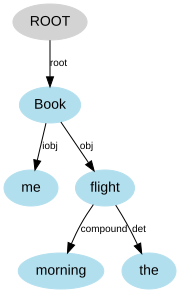

In [15]:
import graphviz

# Create a directed graph
dot = graphviz.Digraph(comment='Dependency Tree', format='png')

# Set graph attributes for a clean look
dot.attr(rankdir='TB', size='8,5')
dot.attr('node', shape='ellipse', style='filled', color='lightblue2', fontname='Arial')
dot.attr('edge', fontname='Arial', fontsize='10')

# Add the root node
dot.node('ROOT', 'ROOT', color='lightgrey')

# Add nodes and directed edges from heads to dependents
for relation in result["dependency_tree"]:
    head = relation['head']
    dependent = relation['dependent']
    label = relation['relation']

    # Ensure both head and dependent nodes exist in the graph
    dot.node(head)
    dot.node(dependent)

    # Add a directed edge indicating the dependency direction (head -> dependent)
    dot.edge(head, dependent, label=label)

# Display the graph directly in the Colab notebook
display(dot)